# Bike Rental Prediction

## 1. Introduction

Bike-sharing systems allow people to rent bicycles for travelling from one location to another. These systems are useful for daily transportation and help reduce traffic and pollution.

In this project, we will analyze bike rental data and understand how factors such as temperature, weather, season, holidays, and working days affect bike rental demand.

We will also build Machine Learning regression models to predict the daily number of bike rentals based on environmental and seasonal conditions.

The project uses two datasets:
- `day.csv` – Daily bike rental data.
- `hour.csv` – Hourly bike rental data.

The main goal is to understand rental patterns and predict daily bike rental demand.

## 2. Problem Statement

The main objective of this project is to analyze bike rental data and predict the daily number of bikes rented based on environmental and seasonal conditions.

### Task 1: Data Analysis

Prepare a complete data analysis report using the given bike rental datasets. Understand the data and identify patterns that affect bike rental demand.

### Task 2: Bike Rental Prediction

Build Machine Learning regression models to predict the daily bike rental count using factors such as temperature, humidity, weather, season, and working days.

### Project Goals

- Understand bike rental trends.
- Analyze the effect of weather and seasons on rentals.
- Identify important factors affecting bike rental demand.
- Build multiple regression models.
- Compare model performance.
- Select the best-performing model for production consideration.

## 3. Libraries

In this project, we use Python libraries for data analysis,
visualization, and Machine Learning.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 4. Data Loading

In this section, we load both bike rental datasets using Pandas.

- day.csv contains daily bike rental records.
- hour.csv contains hourly bike rental records.

We will use these datasets for data analysis and prediction.

In [2]:
day_df = pd.read_csv("../data/day.csv")
hour_df = pd.read_csv("../data/hour.csv")

In [3]:
display(day_df.head())
display(hour_df.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("Daily dataset shape:", day_df.shape)
print("Hourly dataset shape:", hour_df.shape)

Daily dataset shape: (731, 16)
Hourly dataset shape: (17379, 17)


In [5]:
print("Daily dataset columns:")
print(day_df.columns.to_list())
print("\nHourly dataset columns:")
print(hour_df.columns.to_list())

Daily dataset columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Hourly dataset columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


###  Observations

- The daily dataset contains 731 rows and 16 columns.
- The hourly dataset contains 17,379 rows and 17 columns.
- Both datasets contain information about bike rentals, weather, seasons, and working days.
- The hourly dataset has an additional `hr` column that represents the hour of the day.
- Both datasets contain the target column `cnt`, which represents the total number of rented bikes.

**Conclusion:** Both datasets have been loaded successfully. We will use the daily dataset for our main prediction task and both datasets for data analysis.

## 5. Data Understanding

In this section, we will understand the structure and characteristics
of both datasets.

We will check their data types, statistical information,
missing values, duplicate records, and unique values.

### 5.1 Dataset Information

In [6]:
print("Daily dataset information:")
day_df.info()

Daily dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [7]:
print("Hourly dataset information:")
hour_df.info()

Hourly dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


### 5.2 Statistical Summary

We use the describe() function to understand the
distribution of numerical columns.

It provides count, mean, standard deviation,
minimum, maximum, and quartile values.

In [8]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [9]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


### 5.3 Checking Missing Values

We check missing values in both datasets to identify
columns that contain incomplete records.

In [10]:
print("Daily dataset missing values:")
print(day_df.isnull().sum().sum())
print("\nHourly dataset missing values:")
print(hour_df.isnull().sum().sum())

Daily dataset missing values:
0

Hourly dataset missing values:
0


### Observations:

**5.1 Dataset Information:**
- The daily dataset contains 731 rows and 16 columns.
- The hourly dataset contains 17,379 rows and 17 columns.
- The daily dataset has 11 integer columns, 4 float columns, and 1 object column.
- Both datasets contain complete records with non-null values in every column.
- The `dteday` column is stored as an object data type and can be converted to datetime during cleaning.

**5.2 Statistical Summary:**
- The average daily bike rental count (`cnt`) is approximately 4,504.
- The average hourly bike rental count (`cnt`) is approximately 189.
- In the daily dataset, the minimum rental count is 22 and the maximum is 8,714.
- In the hourly dataset, the minimum rental count is 1 and the maximum is 977.
- Registered users have a higher average rental count than casual users in both datasets.
- Temperature, feeling temperature, humidity, and wind speed are stored as normalized values.

**5.3 Checking Missing Values:**
- The daily dataset contains 0 missing values.
- The hourly dataset also contains 0 missing values.
- No missing value treatment is required for either dataset.

**Overall Conclusion:**

Both datasets contain useful information about bike rental patterns. They have complete records and provide numerical and categorical information for further analysis. We will perform additional data quality checks during the cleaning section.

## 6. Data Cleaning

In this section, we will clean both datasets and check their data quality. This step helps us prepare reliable data for exploratory data analysis and machine learning.

The following steps will be performed:

- Check duplicate records.
- Convert date columns into datetime format.
- Verify data types.
- Check invalid or unusual values.

### 6.1 Checking Duplicate Records

Duplicate records are repeated rows in a dataset. We check for duplicates to avoid repeated information affecting our analysis.

In [11]:
print("Daily dataset duplicates:")
print(day_df.duplicated().sum())
print("\nHourly dataset duplicates:")
print(hour_df.duplicated().sum())

Daily dataset duplicates:
0

Hourly dataset duplicates:
0


### 6.2 Converting Date Column

The `dteday` column is currently stored as an object data type. We will convert it into datetime format so that we can work with dates easily during analysis.

In [12]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

print("Daily dataset date type:", day_df['dteday'].dtype)
print("Hourly dataset date type:", hour_df['dteday'].dtype)

Daily dataset date type: datetime64[ns]
Hourly dataset date type: datetime64[ns]


### 6.3 Checking Data Types

We check the data types of all columns to understand how the data is stored. This helps us identify columns that may need further conversion or correction.

In [13]:
print("Daily Dataset Data Types:")
print(day_df.dtypes)

print("\nHourly Dataset Data Types:")
print(hour_df.dtypes)

Daily Dataset Data Types:
instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

Hourly Dataset Data Types:
instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt 

### 6.4 Checking Invalid Values and Outliers

In this section, we check for unusual values in the environmental columns.

We specifically check:
- Zero values in the `hum` column.
- Outliers in the `windspeed` column using the IQR method.

These checks help us identify unusual observations before proceeding with further analysis.

In [14]:
print("Daily dataset - Zero humidity:")
print((day_df['hum'] == 0).sum())

print("\nHourly dataset - Zero humidity:")
print((hour_df['hum'] == 0).sum())

Daily dataset - Zero humidity:
1

Hourly dataset - Zero humidity:
22


In [15]:
def check_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower) | (df[column] > upper)]

    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Outliers:", len(outliers))

print("Daily Dataset - Windspeed Outliers")
check_outliers(day_df, 'windspeed')

print("\nHourly Dataset - Windspeed Outliers")
check_outliers(hour_df, 'windspeed')

Daily Dataset - Windspeed Outliers
Lower Limit: -0.012446750000000034
Upper Limit: 0.38061125
Outliers: 13

Hourly Dataset - Windspeed Outliers
Lower Limit: -0.1193
Upper Limit: 0.4775
Outliers: 342


### Observations:

- The daily dataset contains 1 record with zero humidity.
- The hourly dataset contains 22 records with zero humidity.
- All zero-humidity records belong to 10 March 2011.
- These zero values are considered suspicious and require treatment.
- The IQR method identified 13 windspeed outliers in the daily dataset.
- The hourly dataset contains 342 windspeed outliers.
- The windspeed outliers may represent actual weather conditions, so they should not be removed without further investigation.

**Conclusion:** Zero humidity values were identified as suspicious, while windspeed outliers were detected for further consideration.

### 6.5 Handling Zero Humidity Values

The zero values in the `hum` column are considered invalid. We replace them with the median humidity of each dataset to avoid using suspicious zero values in further analysis.

Windspeed outliers will be retained because they may represent genuine weather conditions.

In [16]:
day_median = day_df.loc[day_df['hum'] > 0, 'hum'].median()
hour_median = hour_df.loc[hour_df['hum'] > 0, 'hum'].median()

day_df.loc[day_df['hum'] == 0, 'hum'] = day_median
hour_df.loc[hour_df['hum'] == 0, 'hum'] = hour_median

In [17]:
print("Daily zero humidity:", (day_df['hum'] == 0).sum())
print("Hourly zero humidity:", (hour_df['hum'] == 0).sum())

Daily zero humidity: 0
Hourly zero humidity: 0


### 6.6 Checking Unique Values

We check the unique values in categorical columns to understand the different categories present in the datasets. This also helps identify unexpected or invalid category values.

In [18]:
categorical_columns = [
    'season', 'yr', 'mnth', 'holiday',
    'weekday', 'workingday', 'weathersit'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print("Daily:", sorted(day_df[col].unique()))
    print("Hourly:", sorted(hour_df[col].unique()))


season:
Daily: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Hourly: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

yr:
Daily: [np.int64(0), np.int64(1)]
Hourly: [np.int64(0), np.int64(1)]

mnth:
Daily: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Hourly: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

holiday:
Daily: [np.int64(0), np.int64(1)]
Hourly: [np.int64(0), np.int64(1)]

weekday:
Daily: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Hourly: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

workingday:
Daily: [np.int64(0), np.int64(1)]
Hourly: [np.int64(0), np.int64(1)]

weathersit:
Daily: [np.int64(1), np.int64(2), np.int64(3)]
Hourly: [np.int64(1), np

###  Overall Observations:

- Duplicate records were checked in both datasets.
- The `dteday` column was successfully converted from object to datetime format.
- All columns have appropriate data types for further analysis.
- Unique values in categorical columns were checked.
- The categorical columns contain expected values, with no unexpected categories found.
- Both datasets have no missing values, as confirmed in Section 5.3.

**Conclusion:**

Both datasets have been checked for basic data quality issues. The date format has been corrected, data types have been verified, and categorical values have been reviewed. The datasets are ready for further exploratory data analysis.

## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) helps us understand patterns, trends, and relationships in the dataset using statistics and visualizations.

In this section, we will analyze bike rental patterns based on seasons, months, working days, holidays, weather conditions, and user types.

We will use both daily and hourly datasets to understand bike rental demand.

### 7.1 Mapping Categories to Readable Names

The `season` and `weathersit` columns contain numerical category values. We create new columns with readable names to make our charts easier to understand.

We will keep the original numerical columns unchanged for machine learning.

In [19]:
season_map = {
    1: 'Winter',
    2: 'Spring',
    3: 'Summer',
    4: 'Fall'
}

weather_map = {
    1: 'Clear',
    2: 'Mist',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain'
}

for df in [day_df, hour_df]:
    df['season_name'] = df['season'].map(season_map)
    df['weather_name'] = df['weathersit'].map(weather_map)

### 7.2 Bike Rentals by Season

In this section, we analyze how bike rental counts vary across different seasons.

We use the daily dataset and calculate the average number of bike rentals for each season.

In [20]:
season_rentals = day_df.groupby(by='season_name').agg({'cnt':'mean'})
season_rentals

,cnt
season_name,
Fall,4728.162921
Spring,4992.331522
Summer,5644.303191
Winter,2604.132597


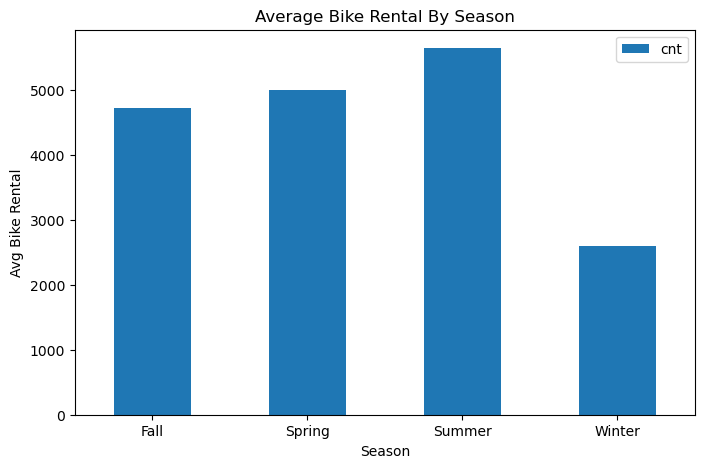

In [21]:
season_rentals.plot(kind='bar', figsize=(8,5))
plt.title("Average Bike Rental By Season")
plt.xlabel("Season")
plt.ylabel("Avg Bike Rental")
plt.xticks(rotation=0)
plt.show()

#### Observation

- Summer has the highest average bike rental count, at approximately 5,650.
- Spring has the second-highest average, at approximately 5,000.
- Fall has an average of approximately 4,700 bike rentals.
- Winter has the lowest average, at approximately 2,600.
- Bike rental demand is higher during warmer seasons and lower during winter.

**Overall Observation:** Season has an impact on bike rental demand. Summer shows the highest average rentals, while winter shows the lowest.

### 7.3 Bike Rentals by Month

In this section, we analyze the average bike rental count for each month to understand how rental demand changes throughout the year.

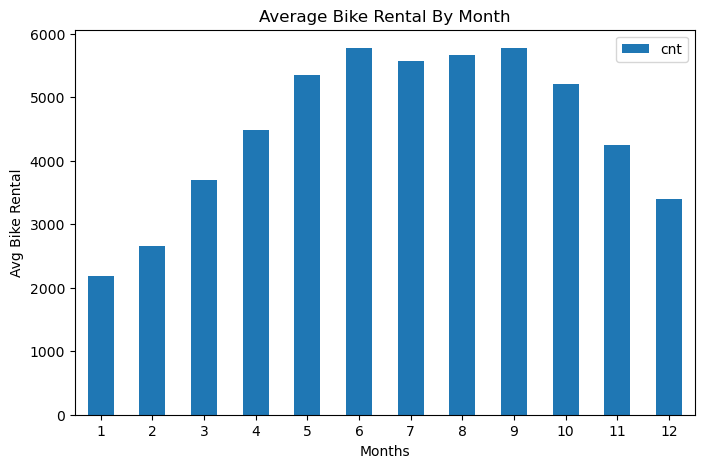

In [22]:
monthly_rentals = day_df.groupby(by='mnth').agg({'cnt':'mean'})
monthly_rentals.plot(kind= 'bar', figsize=(8, 5))
plt.title("Average Bike Rental By Month")
plt.xlabel("Months")
plt.ylabel("Avg Bike Rental")
plt.xticks(rotation=0)
plt.show()

### Observations:

- January has the lowest average bike rentals, approximately 2,176.
- Bike rental demand gradually increases from January to June.
- June has the highest average bike rentals, approximately 5,772.
- July shows a slight decrease in rental demand.
- August and September also have high rental demand, with September averaging approximately 5,767 rentals.
- From October onwards, bike rental demand starts decreasing.
- November and December show lower rental demand compared to the summer months.

**Conclusion:** Bike rental demand is highest during June and September, while January has the lowest demand. Rental demand generally increases during the first half of the year and decreases towards the end of the year.

### 7.4 Bike Rentals by Working Day

In this section, we analyze the average bike rental count on working days and non-working days to understand how people's daily routines affect bike rental demand.

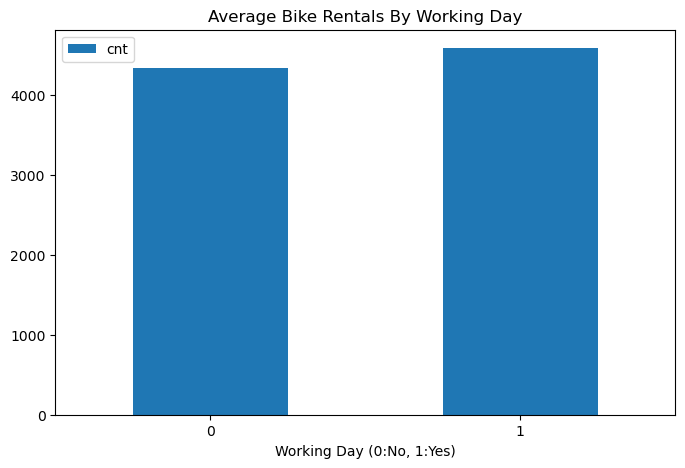

In [23]:
workingday_rentals = day_df.groupby(by='workingday').agg({'cnt':'mean'})
workingday_rentals.plot(kind='bar', figsize=(8,5))
plt.title("Average Bike Rentals By Working Day")
plt.xlabel("Working Day (0:No, 1:Yes)")
plt.xticks(rotation=0)
plt.show()

### Observations:

- The average bike rentals on non-working days (0) are approximately 4,330.
- The average bike rentals on working days (1) are approximately 4,585.
- Bike rentals are slightly higher on working days compared to non-working days.
- The difference in average rentals between working and non-working days is relatively small.

**Conclusion:** Bike rental demand is slightly higher on working days. However, the difference is not very significant.

### 7.5 Bike Rentals by Weather Condition

In this section, we analyze how different weather conditions affect bike rental demand using the daily dataset.

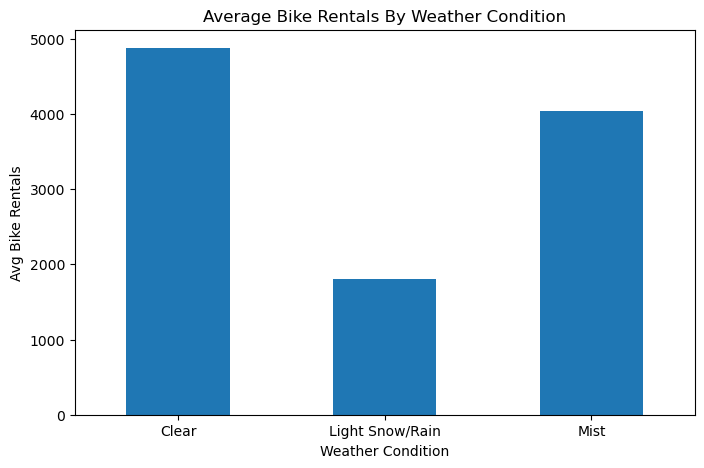

In [24]:
weather_rentals = day_df.groupby('weather_name')['cnt'].mean()
weather_rentals.plot(kind='bar', figsize=(8,5))
plt.title("Average Bike Rentals By Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Avg Bike Rentals")
plt.xticks(rotation=0)
plt.show()

### Observations:

- Weather condition `Clear` has the highest average bike rentals, approximately 4,877.
- Weather condition `Mist` has an average of approximately 4,036 bike rentals.
- Weather condition `Light Snow/Rain` has the lowest average bike rentals, approximately 1,803.
- Bike rental demand decreases as weather conditions become less favorable.
- There is a noticeable difference in rental demand between weather conditions `Clear` and `Light Snow/Rain`.

**Conclusion:** Bike rental demand is highest during clear or favorable weather conditions and lowest during poor weather conditions. This indicates that weather has an impact on bike rental demand.

### 7.6 Casual vs. Registered Users

In this section, we compare casual and registered bike users to understand which type of users contributes more to the total bike rentals.

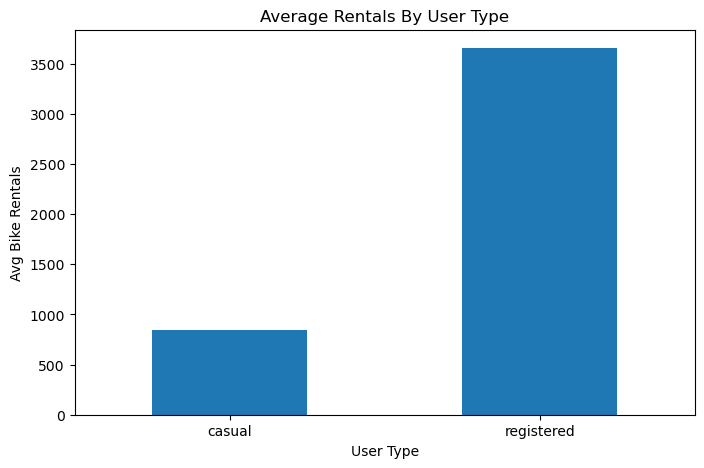

In [25]:
user_rentals = day_df[['casual', 'registered']].mean()
user_rentals.plot(kind='bar', figsize=(8,5))
plt.title("Average Rentals By User Type")
plt.xlabel("User Type")
plt.ylabel("Avg Bike Rentals")
plt.xticks(rotation=0)
plt.show()

### Observations:

- The average number of casual user rentals is approximately 848 per day.
- The average number of registered user rentals is approximately 3,656 per day.
- Registered users contribute significantly more to total bike rentals than casual users.
- The average rentals from registered users are more than four times those from casual users.

**Conclusion:** Registered users contribute the majority of bike rentals. This indicates that regular users play an important role in the bike-sharing system.

### 7.7 Daily Bike Rental Trend

In this section, we analyze daily bike rental counts over time to understand how rental demand changes throughout the dataset period.

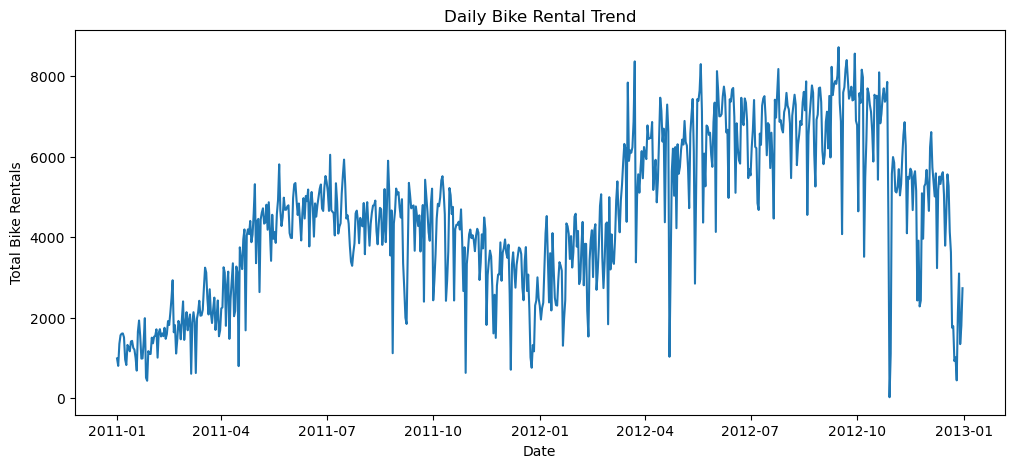

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(day_df['dteday'], day_df['cnt'])

plt.title('Daily Bike Rental Trend')
plt.xlabel('Date')
plt.ylabel('Total Bike Rentals')
plt.show()

### Observations:

- Bike rental demand generally increases from January 2011 to June 2011.
- During the second half of 2011, rental demand fluctuates and shows a slight decline.
- In 2012, bike rental demand increases significantly, especially from April to October.
- The highest rental counts are observed during the middle and later months of 2012.
- Towards the end of 2012, bike rental demand starts decreasing.
- There are noticeable daily fluctuations in rental counts throughout the dataset.

**Conclusion:** Bike rental demand shows an overall increasing trend from 2011 to 2012, with seasonal variations and daily fluctuations. This suggests that time-related factors may influence bike rental demand.

### 7.8 Average Bike Rentals by Hour

In this section, we use the hourly dataset to analyze bike rental demand at different hours of the day.

This analysis helps us identify peak rental hours and understand how rental demand changes throughout the day.

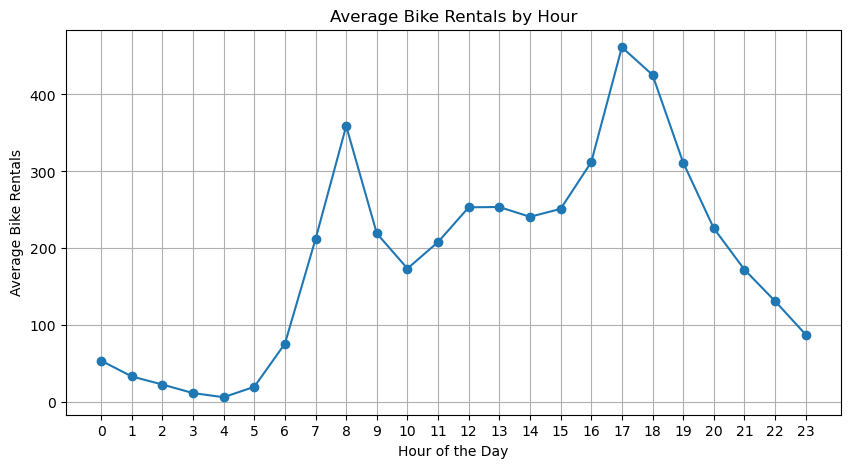

In [27]:
hourly_rentals = hour_df.groupby('hr')['cnt'].mean()
hourly_rentals.plot(kind='line', figsize=(10, 5), marker='o')
plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(0, 24))
plt.grid()
plt.show()

### Observations:

- Bike rental demand is very low during early morning hours, especially between 2 AM and 5 AM.
- The lowest average rental count is at 4 AM, with approximately 6 rentals.
- Rental demand starts increasing from 6 AM and reaches around 359 rentals at 8 AM.
- Bike rentals remain relatively high during the afternoon.
- The highest average bike rental count occurs at 5 PM (17:00), with approximately 461 rentals.
- 6 PM (18:00) also has high demand, with approximately 426 rentals.
- After 6 PM, bike rental demand gradually decreases.

**Conclusion:** Bike rental demand is highest during evening hours, especially around 5 PM and 6 PM. Demand is lowest during early morning hours.

### 7.9 Average Bike Rentals by Weekday

In this section, we analyze the average bike rental count for each day of the week using the hourly dataset.

This helps us understand which weekdays have higher bike rental demand.

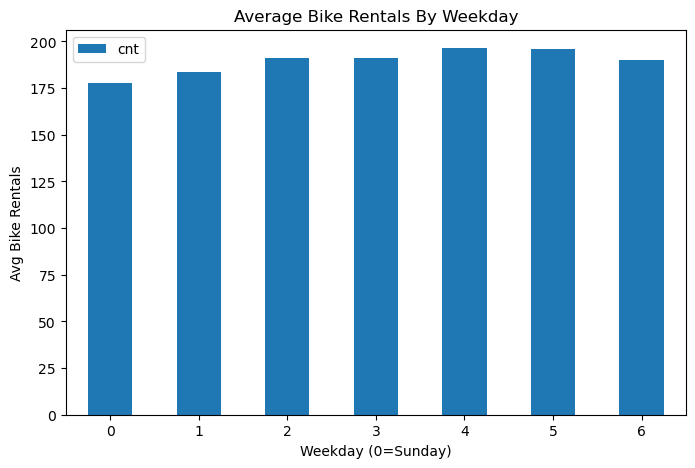

In [28]:
weekday_rentals = hour_df.groupby('weekday').agg({'cnt':'mean'})
weekday_rentals.plot(kind='bar', figsize=(8, 5))
plt.title("Average Bike Rentals By Weekday")
plt.xlabel("Weekday (0=Sunday)")
plt.ylabel("Avg Bike Rentals")
plt.xticks(rotation=0)
plt.show()

### Observations:

- Sunday (0) has the lowest average bike rentals, approximately 177.
- Monday (1) has an average of approximately 184 rentals.
- Rental demand increases slightly during the middle of the week.
- Thursday (4) has the highest average bike rentals, approximately 196.
- Friday (5) also shows high rental demand, with approximately 196 rentals.
- Saturday (6) has an average of approximately 190 rentals.
- The difference in average bike rentals across weekdays is relatively small.

**Conclusion:** Bike rental demand is slightly higher on Thursdays and Fridays, while Sundays have the lowest average demand. Overall, rental demand remains fairly consistent throughout the week.

### 7.10 Average Bike Rentals by Weather – Hourly Dataset

In this section, we analyze how weather conditions affect hourly bike rental demand using the hourly dataset.

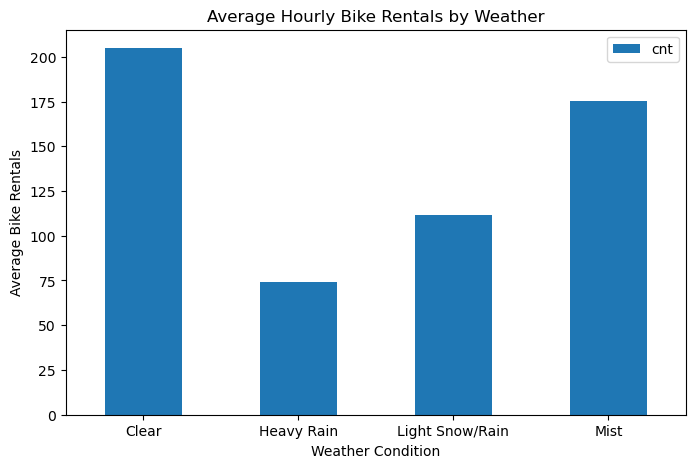

In [29]:
hourly_weather = hour_df.groupby('weather_name').agg({'cnt':'mean'})
hourly_weather.plot(kind='bar', figsize=(8,5))
plt.title('Average Hourly Bike Rentals by Weather')
plt.xlabel('Weather Condition')
plt.ylabel('Average Bike Rentals')
plt.xticks(rotation=0)
plt.show()

### Observations:

- Weather condition `Clear` has the highest average hourly bike rentals, approximately 205.
- Weather condition `Mist` has an average of approximately 175 rentals.
- Weather condition `Light Snow/Rain` has an average of approximately 112 rentals.
- Weather condition `Heavy Rain` has the lowest average hourly rentals, approximately 74.
- Bike rental demand decreases as weather conditions become less favorable.
- The difference between weather condition `Clear` and weather condition `Heavy Rain` is noticeable.

**Conclusion:** Favorable weather conditions have higher hourly bike rental demand, while poor weather conditions have lower demand. This indicates that weather conditions influence hourly bike rentals.

### 7.11 Bike Rentals by Holiday

In this section, we compare the average number of bike rentals on holidays and non-holidays to understand whether holidays affect rental demand.

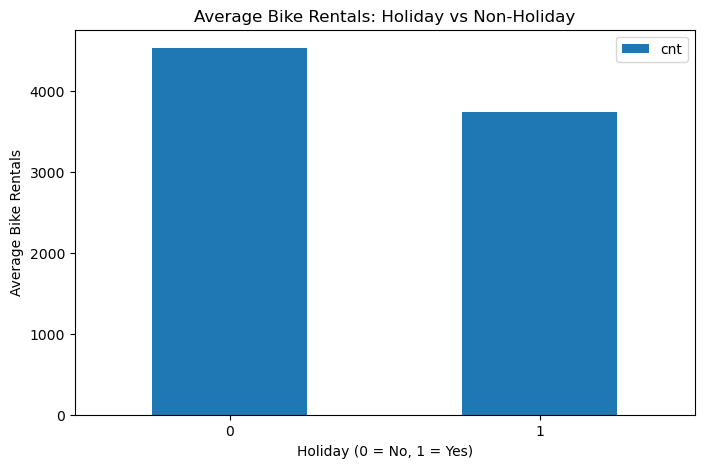

In [30]:
holiday_rentals = day_df.groupby('holiday').agg({'cnt':'mean'})
holiday_rentals.plot(kind='bar', figsize=(8,5))
plt.title('Average Bike Rentals: Holiday vs Non-Holiday')
plt.xlabel('Holiday (0 = No, 1 = Yes)')
plt.ylabel('Average Bike Rentals')
plt.xticks(rotation=0)
plt.show()

#### Observation:

- Average bike rentals are higher on non-holidays than on holidays.
- On non-holidays, the average rentals are approximately 4,500.
- On holidays, the average rentals are approximately 3,700.
- This shows that bike rental demand is slightly lower on holidays compared to regular days.

### 7.12 Temperature vs Bike Rentals

In this section, we use a scatter plot to understand the relationship between temperature and the total number of bike rentals.

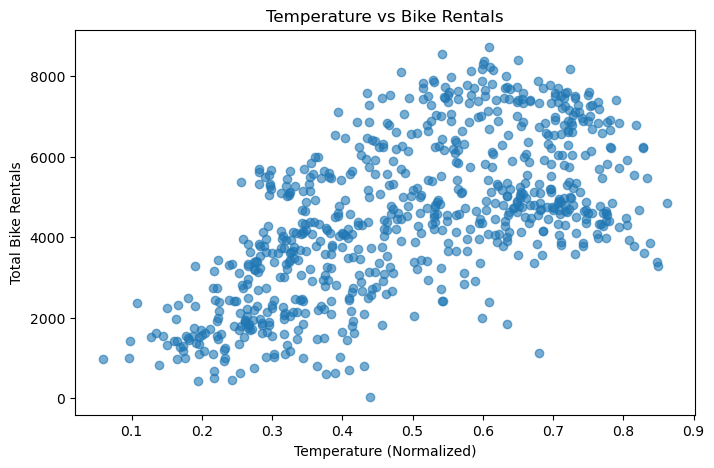

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(day_df['temp'], day_df['cnt'], alpha=0.6)

plt.title('Temperature vs Bike Rentals')
plt.xlabel('Temperature (Normalized)')
plt.ylabel('Total Bike Rentals')
plt.show()

#### Observation:

- The scatter plot shows a positive relationship between temperature and bike rentals.
- As temperature increases, the number of bike rentals generally increases.
- Rental demand is higher at moderate to warm temperatures.
- There is some variation in rentals at similar temperatures, which suggests that other factors also affect bike rental demand.

### 7.13 Correlation Heatmap

In this section, we use a correlation heatmap to understand the relationships between weather conditions and total bike rentals.

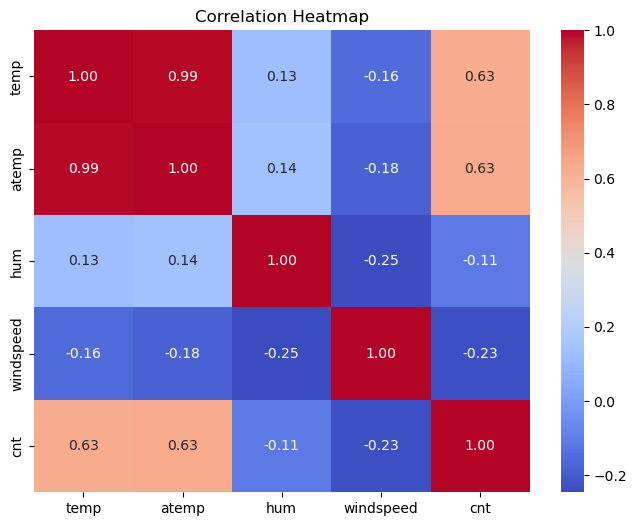

In [32]:
corr_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']

correlation = day_df[corr_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

#### Observation:

- Temperature (`temp`) and feeling temperature (`atemp`) have a moderate positive correlation of 0.63 with bike rentals.
- Humidity (`hum`) has a weak negative correlation of -0.11 with bike rentals.
- Windspeed has a weak negative correlation of -0.23 with bike rentals.
- Temperature and feeling temperature are highly correlated with each other, with a correlation of 0.99.
- This suggests that temperature has a stronger relationship with bike rentals compared to humidity and windspeed.

### 7.14 Hourly Rentals: Working Day vs Non-Working Day

In this section, we compare hourly bike rental patterns on working days and non-working days using a line plot.

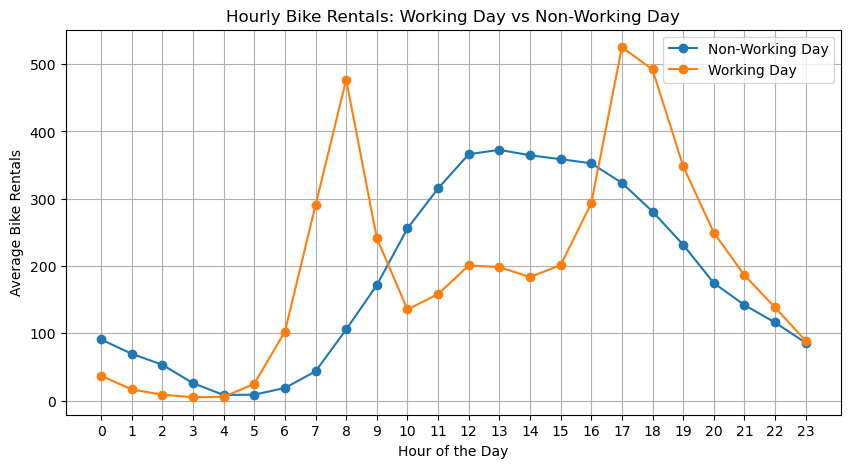

In [33]:
working_hourly = hour_df.groupby(['hr', 'workingday'])['cnt'].mean().unstack()

plt.figure(figsize=(10, 5))

plt.plot(working_hourly.index, working_hourly[0], marker='o', label='Non-Working Day')
plt.plot(working_hourly.index, working_hourly[1], marker='o', label='Working Day')

plt.title('Hourly Bike Rentals: Working Day vs Non-Working Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(0, 24))
plt.legend()
plt.grid()
plt.show()

#### Observation:

- On working days, bike rentals show two major peaks: around 8 AM and 5 PM.
- The highest rental demand on working days occurs around 5 PM.
- On non-working days, rentals are higher during the afternoon, especially between 12 PM and 2 PM.
- Early morning rental demand is generally low on both types of days.
- This suggests that working-day rentals are influenced by office travel timings, while non-working-day rentals are more spread across the afternoon.

### 7.15 Overall EDA Summary

The exploratory data analysis helped us understand the factors that affect bike rental demand.

#### Key Findings:

- **Season:** Bike rentals are highest in Summer and lowest in Winter.
- **Month:** June has the highest average rental demand, while January has the lowest.
- **Working Day:** Average rentals are slightly higher on working days.
- **Holiday:** Rental demand is lower on holidays compared to non-holidays.
- **Weather:** Clear weather has higher rental demand, while poor weather conditions reduce rentals.
- **Temperature:** Bike rentals generally increase as temperature rises.
- **Humidity and Windspeed:** Both show weak negative correlations with bike rentals.
- **User Type:** Registered users contribute more rentals than casual users.
- **Hourly Pattern:** Working days show morning and evening peaks, while non-working days show higher afternoon demand.

#### Conclusion:

Season, temperature, weather conditions, and time of day are important factors related to bike rental demand. These findings will help us select useful features for building the prediction model.

## 8. Data Preprocessing

Data preprocessing is an important step before building machine learning models. In this section, we prepare the daily bike rental dataset for prediction.

We will select the required input features, separate the target variable, and split the dataset into training and testing data.

The main goal is to prepare clean and suitable data for training and evaluating machine learning models.

### 8.1 Selecting Features and Target Variable

In this section, we select the input features and target variable for our prediction model.

The target variable is `cnt`, which represents the total number of bike rentals.

We exclude `casual` and `registered` because their sum is already equal to `cnt`. We also exclude `instant` and `dteday` because they are not required as direct input features for this initial model.

In [34]:
day_df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt', 'season_name', 'weather_name'],
      dtype='object')

In [35]:
X = day_df[['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']]
y = day_df['cnt']

In [36]:
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (731, 11)
Target shape: (731,)


### 8.2 Splitting the Dataset

In this section, we split the dataset into training and testing sets.

We use 80% of the data for training the models and 20% for testing their performance. We use `random_state=42` to get a consistent split whenever we run the code.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [38]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (584, 11)
X_test shape: (147, 11)
y_train shape: (584,)
y_test shape: (147,)


### 8.3 Feature Scaling

In this section, we apply feature scaling using StandardScaler.

Feature scaling helps bring numerical features to a similar scale. We fit the scaler using training data and use the same scaler to transform testing data.

In [39]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (584, 11)
Scaled testing data shape: (147, 11)


## 9. Model Building

In this section, we build machine learning models to predict daily bike rental counts.

We will train different regression algorithms using the prepared training dataset and compare their performance.

The following models will be used:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor

The models will be evaluated using the testing dataset to identify which model performs better.

### 9.1 Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict continuous values.

It tries to identify the relationship between input features and the target variable.

In this project, we use Linear Regression to predict the total number of daily bike rentals (`cnt`).

In [41]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

In [42]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': lr_pred
})

display(comparison.head(10))

,Actual,Predicted
0,6606,6193.800753
1,1550,1579.912076
2,3747,3066.462271
3,6041,4316.434516
4,7538,6760.672128
5,7264,7221.262454
6,1605,810.134770
7,2209,2124.755711
8,7499,7159.927388
9,5743,6434.989846


#### Observation:

- The model successfully generated predictions for the bike rental counts.
- Some predicted values are close to the actual values.
- For example, the actual rental count of 1,550 was predicted as approximately 1,580.
- However, there are also noticeable differences between actual and predicted values.
- This shows that the model can identify some rental patterns, but its prediction errors need to be evaluated further.

### 9.2 Decision Tree Regressor

Decision Tree Regressor is a supervised machine learning algorithm used for predicting continuous values.

It works by dividing the data into smaller groups based on feature conditions and uses these divisions to make predictions.

In this project, we use Decision Tree Regressor to predict daily bike rental counts.

In [43]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

In [44]:
comparison = pd.DataFrame({
    'Actual': y_test.values, 
    'Predicted': dt_pred
})
display(comparison.head(10))

,Actual,Predicted
0,6606,7509.0
1,1550,1450.0
2,3747,3613.0
3,6041,3510.0
4,7538,7525.0
5,7264,7347.0
6,1605,1538.0
7,2209,2808.0
8,7499,6879.0
9,5743,5464.0


#### Observation:

- The Decision Tree model successfully generated predictions for the bike rental counts.
- Some predictions are very close to the actual values.
- For example, the actual rental count of 7,538 was predicted as 7,525.
- However, some predictions show noticeable differences. For example, the actual count of 6,041 was predicted as 3,510.
- This shows that the model performs well for some records but makes larger errors for others.

### 9.3 Random Forest Regressor

Random Forest Regressor is an ensemble machine learning algorithm that uses multiple decision trees to make predictions.

It combines the predictions from different trees to produce a final result.

In this project, we use Random Forest Regressor to predict daily bike rental counts.

In [45]:
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [46]:
comparison = pd.DataFrame({
    'Actual': y_test.values, 
    'Predicted': rf_pred
})
display(comparison.head(10))

,Actual,Predicted
0,6606,6754.90
1,1550,1547.78
2,3747,3412.51
3,6041,4743.72
4,7538,7483.41
5,7264,7332.29
6,1605,1486.95
7,2209,2312.42
8,7499,7217.41
9,5743,6470.08


#### Observation:

- The Random Forest model successfully generated predictions close to the actual rental counts for several records.
- For example, the actual rental count of 1,550 was predicted as approximately 1,548.
- Similarly, the actual count of 7,538 was predicted as approximately 7,483.
- However, some predictions still have noticeable differences. For example, the actual count of 6,041 was predicted as approximately 4,744.
- Overall, the model shows good prediction results for several records, but its performance needs to be confirmed using evaluation metrics.

### 9.4 Gradient Boosting Regressor

Gradient Boosting Regressor is an ensemble machine learning algorithm that builds multiple decision trees one after another.

Each new tree tries to reduce the errors made by the previous trees.

In this project, we use Gradient Boosting Regressor to predict daily bike rental counts.

In [47]:
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

In [48]:
comparison = pd.DataFrame({
    'Actual': y_test.values,  
    'Predicted': gb_pred
})
display(comparison.head(10))

,Actual,Predicted
0,6606,6735.195082
1,1550,1563.859321
2,3747,3585.818926
3,6041,4482.161590
4,7538,7322.053970
5,7264,7179.017845
6,1605,1614.638853
7,2209,2111.880403
8,7499,7207.751327
9,5743,6664.936033


#### Observation:

- The Gradient Boosting model successfully generated predictions for the bike rental counts.
- Some predictions are very close to the actual values.
- For example, the actual rental count of 1,550 was predicted as approximately 1,564.
- Similarly, the actual count of 1,605 was predicted as approximately 1,615.
- However, some predictions show noticeable differences. For example, the actual count of 6,041 was predicted as approximately 4,482.
- This shows that the model performs well for some records but still makes errors in other predictions.

## 10. Model Evaluation

In this section, we evaluate the performance of all four trained regression models.

We compare the actual bike rental counts with the predicted values using different evaluation metrics.

The following metrics will be used:

1. Mean Absolute Error (MAE)
2. Mean Squared Error (MSE)
3. Root Mean Squared Error (RMSE)
4. R² Score

These metrics will help us understand how accurately each model predicts daily bike rental demand and identify the best-performing model.

### 10.1 Evaluation Metrics

We use MAE, MSE, RMSE, and R² Score to evaluate the performance of our regression models.

These metrics help us measure prediction errors and understand how well each model performs on unseen data.

In [49]:
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2score = r2_score(y_test, lr_pred)

In [50]:
print("Linear Regression Evaluation:")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2score)

Linear Regression Evaluation:
MAE: 616.516360027569
MSE: 689070.2256023433
RMSE: 830.102539209671
R2 Score: 0.8281569941431458


#### Observation:

- The Mean Absolute Error (MAE) is approximately 616.52, which means the model's predictions are off by around 617 bike rentals on average.
- The Mean Squared Error (MSE) is approximately 689070.23.
- The Root Mean Squared Error (RMSE) is approximately 830.10, indicating the typical prediction error in terms of bike rental counts, with larger errors having more influence.
- The R² Score is 0.8282, which means the model explains approximately 82.82% of the variation in daily bike rentals.
- Overall, Linear Regression shows a good fit, but some prediction errors are still present.

### 10.2 Decision Tree Evaluation

In this section, we evaluate the Decision Tree Regressor using MAE, MSE, RMSE, and R² Score.

These metrics help us understand how accurately the model predicts daily bike rental counts.

In [51]:
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2score = r2_score(y_test, dt_pred)

In [52]:
print("Decision Tree Evaluation:")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2score)

Decision Tree Evaluation:
MAE: 662.8027210884354
MSE: 968219.2653061225
RMSE: 983.9813338199676
R2 Score: 0.7585417237651239


#### Observation:

- The Decision Tree model achieved an MAE of 662.80, which means its predictions are off by around 663 bike rentals on average.
- The MSE is 968,219.27 and the RMSE is 983.98, showing that the model makes some large prediction errors.
- The R² score is 0.7585, meaning the model explains approximately 75.85% of the variation in bike rental counts.
- Compared with Linear Regression, the Decision Tree has higher error values and a lower R² score.
- Therefore, Linear Regression performs better than Decision Tree on this test dataset.

### 10.3 Random Forest Evaluation

In this section, we evaluate the Random Forest model using four evaluation metrics: MAE, MSE, RMSE, and R² Score.

These metrics help us understand how close the model's predictions are to the actual bike rental counts.

In [53]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2score = r2_score(y_test, rf_pred)

In [54]:
print("Random Forest Evaluation:")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2score)

Random Forest Evaluation:
MAE: 430.1921768707483
MSE: 459569.2764088435
RMSE: 677.9153903023913
R2 Score: 0.8853908311180895


#### Observation:

- The Random Forest model achieved an MAE of 430.19, which means its predictions are off by around 430 bike rentals on average.
- The MSE is 459,569.28 and the RMSE is 677.92, showing lower prediction errors compared to the previous two models.
- The R² score is 0.8854, meaning the model explains approximately 88.54% of the variation in bike rental counts.
- Compared with Linear Regression and Decision Tree, Random Forest has lower error values and a higher R² score.
- Therefore, Random Forest performs better than the previous two models on this test dataset.

### 10.4 Gradient Boosting Evaluation

In this section, we evaluate the Gradient Boosting model using MAE, MSE, RMSE, and R² Score.

These metrics help us compare its prediction performance with the other models.

In [55]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2score = r2_score(y_test, gb_pred)

In [56]:
print("Gradient Boosting Evaluation:")
print("MAE:", gb_mae)
print("MSE:", gb_mse)
print("RMSE:", gb_rmse)
print("R2 Score:", gb_r2score)

Gradient Boosting Evaluation:
MAE: 458.41824354641324
MSE: 415028.7934159374
RMSE: 644.2272839735502
R2 Score: 0.8964985095453883


#### Observation:

- The Gradient Boosting model achieved an MAE of 458.42, which means its predictions are off by around 458 bike rentals on average.
- The MSE is 415,028.79 and the RMSE is 644.23, showing that the model has lower squared prediction errors compared to the other models.
- The R² score is 0.8965, meaning the model explains approximately 89.65% of the variation in bike rental counts.
- Compared with the other models, Gradient Boosting achieved the lowest MSE and RMSE and the highest R² score.
- Random Forest has a slightly lower MAE than Gradient Boosting.
- Overall, Gradient Boosting performs best across most evaluation metrics.

### 10.5 Model Comparison

In this section, we compare all four trained models using MAE, MSE, RMSE, and R² Score.

This comparison helps us identify which model performs best for predicting daily bike rental counts.

In [57]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'MAE': [lr_mae, dt_mae, rf_mae, gb_mae],
    'MSE': [lr_mse, dt_mse, rf_mse, gb_mse],
    'RMSE': [lr_rmse, dt_rmse, rf_rmse, gb_rmse],
    'R2 Score': [lr_r2score, dt_r2score, rf_r2score, gb_r2score]
})

model_comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,616.516360,689070.225602,830.102539,0.828157
1,Decision Tree,662.802721,968219.265306,983.981334,0.758542
2,Random Forest,430.192177,459569.276409,677.915390,0.885391
3,Gradient Boosting,458.418244,415028.793416,644.227284,0.896499


#### Observation:

- All four models were evaluated using MAE, MSE, RMSE, and R² Score.
- Linear Regression performed reasonably well but had higher prediction errors than the ensemble models.
- Decision Tree showed the highest prediction errors and the lowest R² score.
- Random Forest achieved the lowest MAE of 430.19, meaning it has the lowest average absolute prediction error.
- Gradient Boosting achieved the lowest MSE of 415,028.79, the lowest RMSE of 644.23, and the highest R² score of 0.8965.
- Overall, Gradient Boosting performed best across most evaluation metrics, while Random Forest performed best in terms of MAE.

Therefore, Gradient Boosting is selected as the best overall model for predicting daily bike rental counts.

### 10.6 Evaluation Summary:

- Four regression models were evaluated: Linear Regression, Decision Tree, Random Forest, and Gradient Boosting.
- Linear Regression and Decision Tree showed higher prediction errors compared to the ensemble models.
- Random Forest achieved the lowest MAE of 430.19.
- Gradient Boosting achieved the lowest MSE of 415,028.79, the lowest RMSE of 644.23, and the highest R² score of 0.8965.
- Based on the overall comparison, Gradient Boosting was selected as the best-performing model for this project.
- The selected model explains approximately 89.65% of the variation in daily bike rental counts on the test dataset.

## 11. Hyperparameter Tuning
In this section, we will try different settings for all four models using GridSearchCV. We will compare their performance before and after tuning to find the best model for bike rental prediction.

### 11.1 Linear Regression Tuning

In this section, we use GridSearchCV to test different settings of Linear Regression and find the best configuration using 5-fold cross-validation.

In [58]:
lr_param_grid = {
    'fit_intercept': [True, False]
}

lr_grid = GridSearchCV(
    estimator=lr_model, 
    param_grid= lr_param_grid, 
    cv=5, 
    scoring='neg_mean_squared_error', 
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

,estimator,LinearRegression()
,param_grid,"{'fit_intercept': [True, False]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,fit_intercept,True


In [59]:
print("Best Parameters:", lr_grid.best_params_)
print("Best CV MSE:", -lr_grid.best_score_)

Best Parameters: {'fit_intercept': True}
Best CV MSE: 824059.0972855107


In [60]:
lr_tuned_pred = lr_grid.best_estimator_.predict(X_test_scaled)

print("Tuned Linear Regression Evaluation:")
print("MAE:", mean_absolute_error(y_test, lr_tuned_pred))
print("MSE:", mean_squared_error(y_test, lr_tuned_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_tuned_pred)))
print("R2 Score:", r2_score(y_test, lr_tuned_pred))

Tuned Linear Regression Evaluation:
MAE: 616.516360027569
MSE: 689070.2256023433
RMSE: 830.102539209671
R2 Score: 0.8281569941431458


#### Observation:

- GridSearchCV selected `fit_intercept=True` as the best parameter.
- The tuned model produced the same evaluation results as the original model.
- This happened because the original model was already using the best parameter.
- Therefore, tuning did not improve Linear Regression performance.

### 11.2 Decision Tree Tuning

In this section, we use GridSearchCV to test different settings of the Decision Tree model and select the best configuration using 5-fold cross-validation.

In [61]:
dt_param_grid = {
    'max_depth': [3, 5, 10, None], 
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
dt_grid = GridSearchCV(
    estimator=dt_model, 
    param_grid=dt_param_grid, 
    cv=5, 
    scoring='neg_mean_squared_error', 
    n_jobs=-1, 
    verbose=2
)
dt_grid.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,DecisionTreeR...ndom_state=42)
,param_grid,"{'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [62]:
print("Best Parameters:", dt_grid.best_params_)
print("Best CV MSE:", -dt_grid.best_score_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV MSE: 823118.2654048738


In [63]:
dt_tuned_pred = dt_grid.best_estimator_.predict(X_test)

print("Tuned Decision Tree Evaluation:")
print("MAE:", mean_absolute_error(y_test, dt_tuned_pred))
print("MSE:", mean_squared_error(y_test, dt_tuned_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, dt_tuned_pred)))
print("R2 Score:", r2_score(y_test, dt_tuned_pred))

Tuned Decision Tree Evaluation:
MAE: 567.71122605266
MSE: 752271.9236410926
RMSE: 867.3361076544044
R2 Score: 0.81239550951835


#### Observation:

- The tuned Decision Tree performed better than the original model across all four evaluation metrics.
- MAE decreased from 662.80 to 567.71.
- RMSE decreased from 983.98 to 867.34.
- R² Score increased from 0.7585 to 0.8124.
- Hyperparameter tuning improved the prediction performance of the Decision Tree model.

### 11.3 Random Forest Tuning

In this section, we use GridSearchCV to test different settings of the Random Forest model and find the best configuration using 5-fold cross-validation.

In [64]:
rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(
    estimator=rf_model, 
    param_grid=rf_param_grid, 
    cv=5, 
    scoring='neg_mean_squared_error', 
    n_jobs=-1,
    verbose=2
)
rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'min_samples_split': [2, 5], 'n_estimators': [50, 100, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,150


In [65]:
print("Best Parameters:", rf_grid.best_params_)
print("Best CV MSE:", -rf_grid.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 150}
Best CV MSE: 509406.4433134041


In [66]:
rf_tuned_pred = rf_grid.best_estimator_.predict(X_test)

print("Tuned Random Forest Evaluation:")
print("MAE:", mean_absolute_error(y_test, rf_tuned_pred))
print("MSE:", mean_squared_error(y_test, rf_tuned_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_tuned_pred)))
print("R2 Score:", r2_score(y_test, rf_tuned_pred))

Tuned Random Forest Evaluation:
MAE: 428.69319727891155
MSE: 454794.95216356765
RMSE: 674.3848694651798
R2 Score: 0.8865814706186227


#### Observation:

- The tuned Random Forest performed slightly better than the original model across all four evaluation metrics.
- MAE decreased from 430.19 to 428.69.
- RMSE decreased from 677.92 to 674.38.
- R² Score increased from 0.8854 to 0.8866.
- Hyperparameter tuning resulted in a small improvement in prediction performance.

### 11.4 Gradient Boosting Tuning

In this section, we use GridSearchCV to test different settings of the Gradient Boosting model and find the best configuration using 5-fold cross-validation.

In [67]:
gb_param_grid = {
    'n_estimators': [150, 200,300],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [2, 4, 6],
    'min_samples_split': [20, 50, 100],
    'min_samples_leaf': [6, 7, 9]
}

gb_grid = GridSearchCV(
    estimator=gb_model,
    param_grid=gb_param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

gb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.05, 0.1, ...], 'max_depth': [2, 4, ...], 'min_samples_leaf': [6, 7, ...], 'min_samples_split': [20, 50, ...], ...}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [68]:
print("Best Parameters:", gb_grid.best_params_)
print("Best CV MSE:", -gb_grid.best_score_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 9, 'min_samples_split': 20, 'n_estimators': 200}
Best CV MSE: 435686.6404978914


In [69]:
gb_tuned_pred = gb_grid.best_estimator_.predict(X_test)

print("Tuned Gradient Boosting Evaluation:")
print("MAE:", mean_absolute_error(y_test, gb_tuned_pred))
print("MSE:", mean_squared_error(y_test, gb_tuned_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, gb_tuned_pred)))
print("R2 Score:", r2_score(y_test, gb_tuned_pred))

Tuned Gradient Boosting Evaluation:
MAE: 445.73496394611874
MSE: 396475.6139307867
RMSE: 629.6630955763461
R2 Score: 0.9011253734156753


#### Observation:

- The tuned Gradient Boosting model performed better than the original model across all four evaluation metrics.
- MAE decreased from 458.42 to 445.73.
- MSE decreased from 415028.79 to 396475.61.
- RMSE decreased from 644.23 to 629.66.
- R² Score increased from 0.8965 to 0.9011.
- The tuned model explains approximately 90.11% of the variation in bike rental counts.
- Overall, hyperparameter tuning improved Gradient Boosting prediction performance.

### 11.5 Original vs Tuned Model Comparison

We compare the evaluation results of all four original and tuned models using MAE, MSE, RMSE, and R² Score.

In [70]:
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting'],

    'Original MAE': [
        lr_mae, dt_mae, rf_mae, gb_mae
    ],
    'Tuned MAE': [
        mean_absolute_error(y_test, lr_tuned_pred),
        mean_absolute_error(y_test, dt_tuned_pred), 
        mean_absolute_error(y_test, rf_tuned_pred), 
        mean_absolute_error(y_test, gb_tuned_pred), 
    ],

    'Original MSE': [
        lr_mse, dt_mse, rf_mse, gb_mse
    ],
    'Tuned MSE': [
        mean_squared_error(y_test, lr_tuned_pred),
        mean_squared_error(y_test, dt_tuned_pred),
        mean_squared_error(y_test, rf_tuned_pred),
        mean_squared_error(y_test, gb_tuned_pred)
    ],

    'Original RMSE': [
        lr_rmse, dt_rmse, rf_rmse, gb_rmse
    ],
    'Tuned RMSE': [
        np.sqrt(mean_squared_error(y_test, lr_tuned_pred)),
        np.sqrt(mean_squared_error(y_test, dt_tuned_pred)),
        np.sqrt(mean_squared_error(y_test, rf_tuned_pred)),
        np.sqrt(mean_squared_error(y_test, gb_tuned_pred)),
    ],

    'Original R2': [
        lr_r2score, dt_r2score, rf_r2score, gb_r2score
    ],
    'Tuned R2': [
        r2_score(y_test, lr_tuned_pred),
        r2_score(y_test, dt_tuned_pred),
        r2_score(y_test, rf_tuned_pred),
        r2_score(y_test, gb_tuned_pred),
    ]
})

display(comparison_df)

,Model,Original MAE,Tuned MAE,Original MSE,Tuned MSE,Original RMSE,Tuned RMSE,Original R2,Tuned R2
0,Linear Regression,616.516360,616.516360,689070.225602,689070.225602,830.102539,830.102539,0.828157,0.828157
1,Decision Tree,662.802721,567.711226,968219.265306,752271.923641,983.981334,867.336108,0.758542,0.812396
2,Random Forest,430.192177,428.693197,459569.276409,454794.952164,677.915390,674.384869,0.885391,0.886581
3,Gradient Boosting,458.418244,445.734964,415028.793416,396475.613931,644.227284,629.663096,0.896499,0.901125


#### Observation:

- **Linear Regression:** There was no change in performance after tuning. All four evaluation metrics remained the same.
- **Decision Tree:** Performance improved after tuning. MAE decreased from 662.80 to 567.71, and R² Score increased from 0.7585 to 0.8124.
- **Random Forest:** There was a small improvement in all four metrics. It achieved the lowest MAE (428.69) among the tuned models.
- **Gradient Boosting:** It achieved the best overall performance after tuning. It has the lowest MSE (396475.61), lowest RMSE (629.66), and highest R² Score (0.9011).

**Overall Conclusion:** Gradient Boosting is the best-performing model based on three out of four evaluation metrics. It explains approximately 90.11% of the variation in bike rental demand. Random Forest has the lowest MAE, meaning its average absolute prediction error is slightly lower.

## 12. Final Model Analysis

In this section, we perform some additional checks on our best-performing model, Gradient Boosting. We will check for overfitting, understand which features are important, and compare actual bike rental counts with predicted values.

### 12.1 Overfitting Check (Train vs Test R²)

We compare the R² Score on the training and testing datasets to check whether our Gradient Boosting model is overfitting.

If the training score is much higher than the testing score, it may indicate overfitting. If both scores are close, the model performs more consistently on both datasets.

In [71]:
y_train_pred = gb_grid.best_estimator_.predict(X_train)
y_test_pred = gb_grid.best_estimator_.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training R2 Score:", train_r2)
print("Testing R2 Score:", test_r2)

Training R2 Score: 0.93621866586281
Testing R2 Score: 0.9011253734156753


#### Observation

- The training R² Score is 0.9362 (93.62%), while the testing R² Score is 0.9011 (90.11%).
- The difference between the two scores is approximately 3.51 percentage points.
- Both scores are close, which indicates that the model performs consistently on training and testing data.
- There is no strong indication of overfitting, and the model generalizes well to unseen data.

### 12.2 Feature Importance

We use the feature importance values from the tuned Gradient Boosting model to understand which features contribute most to predicting bike rental demand.

In [72]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': gb_grid.best_estimator_.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

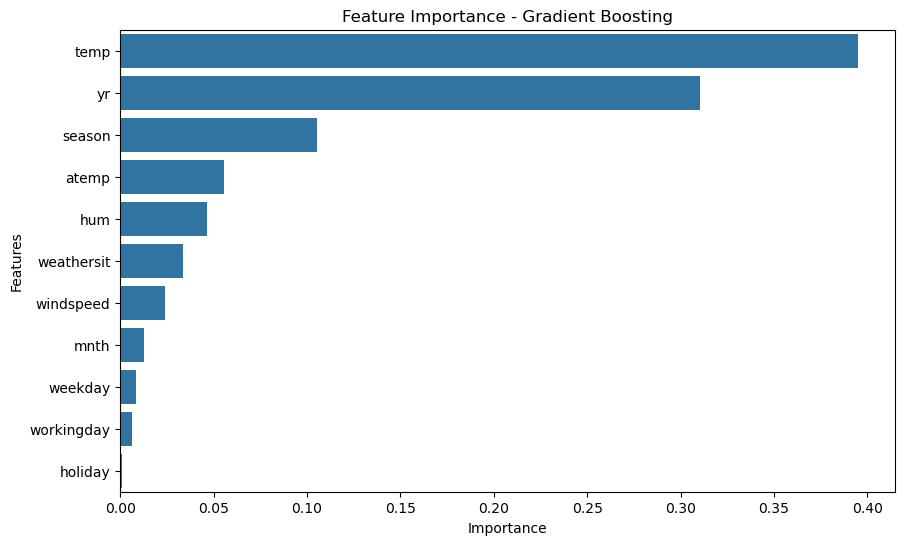

In [73]:
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature')

plt.title('Feature Importance - Gradient Boosting')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

#### Observation

- `temp` is the most important feature, contributing approximately 0.40 to the model's total feature importance.
- `yr` is the second most important feature, with an importance of approximately 0.31.
- `season` is the third most important feature.
- `hum`, `weathersit`, and `windspeed` have a smaller contribution to the predictions.
- `holiday`, `workingday`, and `weekday` have very low feature importance.

**Overall Observation:** Temperature and year are the most influential features in the Gradient Boosting model's predictions. This suggests that weather conditions and yearly changes play an important role in predicting bike rental demand.

### 12.3 Actual vs Predicted Plot

We compare the actual bike rental counts with the values predicted by our tuned Gradient Boosting model. This helps us understand how closely the model's predictions match the actual values.

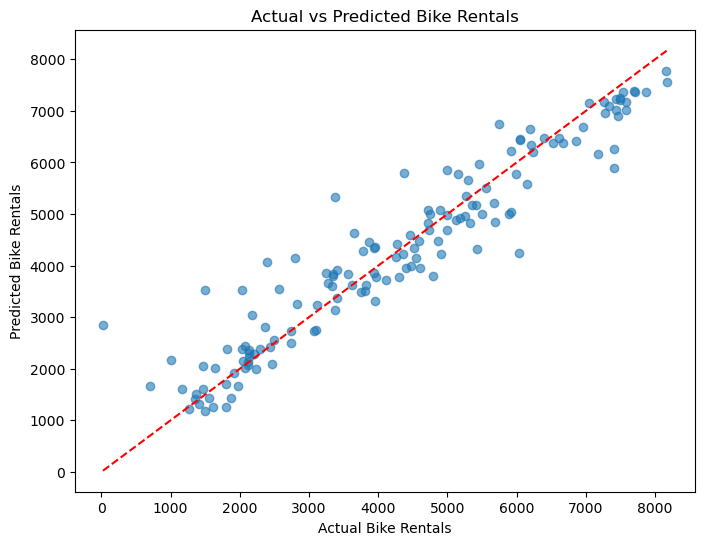

In [74]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, gb_tuned_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Actual vs Predicted Bike Rentals')
plt.xlabel('Actual Bike Rentals')
plt.ylabel('Predicted Bike Rentals')
plt.show()

#### Observation

- Most data points are close to the red dashed line, indicating that the model's predictions are reasonably close to the actual bike rental counts.
- The model performs well for both lower and higher rental counts.
- Some points are away from the line, which indicates prediction errors for certain observations.
- Overall, the plot shows that the Gradient Boosting model captures the general pattern of bike rental demand.

**Overall Observation:** The model provides reasonably accurate predictions, although some differences between actual and predicted values remain.

## 13. Saving the Best Model

In this section, we save the best-performing tuned model so that it can be reused later without training it again. Based on our model comparison, Gradient Boosting is selected as the best overall model.

In [75]:
import joblib

joblib.dump(gb_grid.best_estimator_, '../model/bike_rental_model.pkl')

['../model/bike_rental_model.pkl']

In [76]:
import os

print("Model saved:", os.path.exists('../model/bike_rental_model.pkl'))

Model saved: True


#### Note: Using the Saved Model

The saved Gradient Boosting model can be loaded and used for future predictions without training it again.

While making predictions, we must provide the input features in the same order used during model training:

`season, yr, mnth, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed`

**Important:**
- The model expects all 11 input features.
- The features must be provided in the same order as during training.
- No feature scaling is required because Gradient Boosting was trained using the original, unscaled features.

## 14. Challenges Faced and Solutions

| Challenge | Technique Used | Reason |
|---|---|---|
| `dteday` was stored as text (object type) | Converted it to datetime format | Needed for date-based analysis and the daily trend plot |
| Zero humidity values (1 daily record, 22 hourly records, all on 10 March 2011) | Replaced them with the median humidity | These values were treated as suspicious, and the median is less affected by extreme values |
| Windspeed outliers (13 daily, 342 hourly, found using the IQR method) | Kept them | They appeared to represent genuine weather conditions rather than errors |
| Numeric codes for `season` and `weathersit` were hard to understand | Created readable name columns and kept the original numeric columns | Charts are easier to read, and the models still use numeric data |
| `casual` + `registered` equals the target `cnt` | Removed both from the input features | Using them would cause data leakage |
| `instant` and `dteday` are an index and a date | Removed them from the input features | Other features already capture useful information such as year, month, and weekday |
| `temp` and `atemp` are highly correlated (correlation 0.99) | Kept both features | They contain similar information, but both may still contribute to tree-based model predictions |
| Features were on different scales | Applied StandardScaler to Linear Regression, fitted on training data only | Scaling helps Linear Regression, and fitting on training data only avoids data leakage |
| Default model settings were not the best | Used GridSearchCV with 5-fold cross-validation on the training set | Improved Gradient Boosting R² from 0.8965 to 0.9011 without using the test set for tuning |
| Overfitting risk | Compared training and testing R² (Train R² = 0.9362, Test R² = 0.9011) | Checks how consistently the model performs on unseen data |
| Data has a time trend (2012 is much higher than 2011) and a random split was used | Noted as a limitation | A random split may give slightly optimistic results; splitting by date would be more realistic |

**Overall:** These challenges showed the importance of data cleaning, avoiding data leakage, selecting suitable features, model tuning, and checking for overfitting.

## 15. Conclusion

In this project, we analyzed the bike rental dataset and built machine learning models to predict daily bike rental demand.

We performed data cleaning, exploratory data analysis, and preprocessing to prepare the data for model building. We trained and evaluated four models: Linear Regression, Decision Tree, Random Forest, and Gradient Boosting.

After hyperparameter tuning, Gradient Boosting achieved the best overall performance with an R² Score of 0.9011 and an RMSE of 629.66. Random Forest achieved the lowest MAE of 428.69.

Finally, we saved the tuned Gradient Boosting model as `bike_rental_model.pkl` so that it can be reused for future predictions.

This project helped us understand the complete machine learning process, from data preparation to model evaluation and saving the final model.

**Limitations and Future Work:** The dataset covers only two years (2011 and 2012), and a random train-test split was used even though the data has a time trend, so the scores may be slightly optimistic. Future work can include splitting the data by date, predicting hourly demand using `hour.csv`, and trying other models.